# Late Delivery Prediction for an E-commerce Marketplace (Olist)

**Problem:** Late deliveries cause bad reviews and lost customers. At purchase time, can we flag the orders most likely to arrive after the estimated delivery date, so operations can warn customers and chase carriers?

**Target:** `late = 1` if the order was delivered after the estimated delivery date (built from the order dates).

**Metric:** Only ~8% of orders are late, so accuracy is misleading (always guessing "on time" gives ~92%). I use **PR-AUC** to compare models, and **recall / precision on the late class** to choose how many orders to review.

**Data:** Olist Brazilian E-Commerce Public Dataset (Kaggle), 7 of the 9 tables joined, ~96K delivered orders.
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

**Pipeline of this notebook:** data loading → target and features → train/test split → EDA (train only) → preprocessing pipeline → models and tuning → threshold → test evaluation → error analysis → business recommendation → saving files for the Streamlit app.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## 1. Load the data
The next cell downloads the dataset with the Kaggle API. The first time in a Colab session it asks you to upload your `kaggle.json`; after that it skips the upload.

In [2]:
import os, subprocess

DATA_DIR = "/content/olist"
if not os.path.exists(f"{DATA_DIR}/olist_orders_dataset.csv"):
    kaggle_cfg = os.path.expanduser("~/.kaggle/kaggle.json")
    if not os.path.exists(kaggle_cfg):
        from google.colab import files
        files.upload()  # upload kaggle.json (only needed once per session)
        os.makedirs(os.path.dirname(kaggle_cfg), exist_ok=True)
        os.replace("kaggle.json", kaggle_cfg)
        os.chmod(kaggle_cfg, 0o600)
    subprocess.run("pip install -q kaggle", shell=True, check=True)
    subprocess.run(f"kaggle datasets download -d olistbr/brazilian-ecommerce --unzip -p {DATA_DIR}",
                   shell=True, check=True)
print(sorted(os.listdir(DATA_DIR)))

Saving kaggle.json to kaggle.json
['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


## 2. Data understanding
Tables loaded: orders, order items, products, category translation, customers, sellers and geolocation. `order_status` shows that most orders are `delivered`; canceled, unavailable and in-progress orders have no delivery date, so they cannot be labeled late or on time and are excluded.

In [3]:
p = "/content/olist/"
orders    = pd.read_csv(p + "olist_orders_dataset.csv")
items     = pd.read_csv(p + "olist_order_items_dataset.csv")
customers = pd.read_csv(p + "olist_customers_dataset.csv")
sellers   = pd.read_csv(p + "olist_sellers_dataset.csv")
products  = pd.read_csv(p + "olist_products_dataset.csv")
geo       = pd.read_csv(p + "olist_geolocation_dataset.csv")
trans     = pd.read_csv(p + "product_category_name_translation.csv")

for name, d in [("orders", orders), ("items", items), ("customers", customers),
                ("sellers", sellers), ("products", products), ("geo", geo)]:
    print(name, d.shape)

print(orders["order_status"].value_counts())
print(orders.isnull().sum())
orders.head()

orders (99441, 8)
items (112650, 7)
customers (99441, 5)
sellers (3095, 4)
products (32951, 9)
geo (1000163, 5)
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 3. Target, features and leakage
Only delivered orders with a real delivery date are kept (96,470 orders). Late orders are 8.1% of the data. Missing values are small (category 1,378, distance 478) and are handled inside the pipeline.

Features are limited to what is known **at purchase time**: purchase month / day / hour, promised delivery days, price, freight, product weight and volume, category, seller and customer state, and the distance between seller and customer (haversine). Columns that are only known after purchase (approval, carrier and delivery dates) are used to build the target and then dropped.

Limitation: an order can contain several products or sellers; I keep the first seller and product and record `n_items` and `n_sellers`.

In [4]:
# 1) keep only delivered orders with a real delivery date
date_cols = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]
df = orders[orders["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"]).copy()
for c in date_cols:
    df[c] = pd.to_datetime(df[c])

# 2) target: late = delivered after the estimated date
df["late"] = (df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]).astype(int)

# 3) features known at purchase time
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_dow"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour
df["estimated_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400

# 4) aggregate items to one row per order
items_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "max"),
    price=("price", "sum"),
    freight=("freight_value", "sum"),
    n_sellers=("seller_id", "nunique"),
    seller_id=("seller_id", "first"),
    product_id=("product_id", "first"),
).reset_index()

# 5) product info + English category names
prod = products.merge(trans, on="product_category_name", how="left")
prod["volume_cm3"] = prod["product_length_cm"] * prod["product_height_cm"] * prod["product_width_cm"]
prod = prod[["product_id", "product_category_name_english", "product_weight_g", "volume_cm3"]]
prod = prod.rename(columns={"product_category_name_english": "category"})

# 6) average coordinates per zip prefix
geo_zip = geo.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean")
).reset_index()

cust = customers[["customer_id", "customer_zip_code_prefix", "customer_state"]]
sell = sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]]

# 7) joins
df = (df.merge(items_agg, on="order_id", how="inner")
        .merge(prod, on="product_id", how="left")
        .merge(cust, on="customer_id", how="left")
        .merge(sell, on="seller_id", how="left"))

df = (df.merge(geo_zip.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                                       "lat": "cust_lat", "lng": "cust_lng"}),
               on="customer_zip_code_prefix", how="left")
        .merge(geo_zip.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix",
                                       "lat": "sell_lat", "lng": "sell_lng"}),
               on="seller_zip_code_prefix", how="left"))

# 8) haversine distance (km) between seller and customer
def haversine(lat1, lon1, lat2, lon2):
    r = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df.sell_lat, df.sell_lng, df.cust_lat, df.cust_lng)
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)
df["freight_ratio"] = df["freight"] / (df["price"] + 1)

print(df.shape)
print(df["late"].value_counts())
print(df["late"].value_counts(normalize=True))
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head(3)

(96470, 33)
late
0    88644
1     7826
Name: count, dtype: int64
late
0    0.918876
1    0.081124
Name: proportion, dtype: float64
order_approved_at                 14
order_delivered_carrier_date       1
category                        1378
product_weight_g                  16
volume_cm3                        16
cust_lat                         264
cust_lng                         264
sell_lat                         215
sell_lng                         215
distance_km                      478
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,late,purchase_month,purchase_dow,purchase_hour,estimated_days,n_items,price,freight,n_sellers,seller_id,product_id,category,product_weight_g,volume_cm3,customer_zip_code_prefix,customer_state,seller_zip_code_prefix,seller_state,cust_lat,cust_lng,sell_lat,sell_lng,distance_km,same_state,freight_ratio
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,10,0,10,15.544063,1,29.99,8.72,1,3504c0cb71d7fa48d967e0e4c94d59d9,87285b34884572647811a353c7ac498a,housewares,500.0,1976.0,3149,SP,9350,SP,-23.576983,-46.587161,-23.680729,-46.444238,18.576110,1,0.281381
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,7,1,20,19.137766,1,118.70,22.76,1,289cdb325fb7e7f891c38608bf9e0962,595fac2a385ac33a80bd5114aec74eb8,perfumery,400.0,4693.0,47813,BA,31570,SP,-12.177924,-44.660711,-19.807681,-43.980427,851.495069,0,0.190142
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,8,2,8,26.639711,1,159.90,19.22,1,4869f7a5dfa277a7dca6462dcf3b52b2,aa4383b373c6aca5d8797843e5594415,auto,420.0,9576.0,75265,GO,14840,SP,-16.745150,-48.514783,-21.363502,-48.229601,514.410666,0,0.119453


## 4. Train / test split
The split is done **before** any EDA or fitting (80/20, stratified), so the test set stays untouched until the final evaluation.

In [5]:
from sklearn.model_selection import train_test_split

drop_cols = [
    "order_id", "customer_id", "order_status",
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "seller_id", "product_id",
    "customer_zip_code_prefix", "seller_zip_code_prefix",
    "cust_lat", "cust_lng", "sell_lat", "sell_lng",
]

data = df.drop(columns=drop_cols)
X = data.drop(columns="late")
y = data["late"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())
print(X.dtypes)

(77176, 16) (19294, 16)
0.08112625686741992 0.08111329947133825
purchase_month        int32
purchase_dow          int32
purchase_hour         int32
estimated_days      float64
n_items               int64
price               float64
freight             float64
n_sellers             int64
category             object
product_weight_g    float64
volume_cm3          float64
customer_state       object
seller_state         object
distance_km         float64
same_state            int64
freight_ratio       float64
dtype: object


## 5. EDA (train set only)

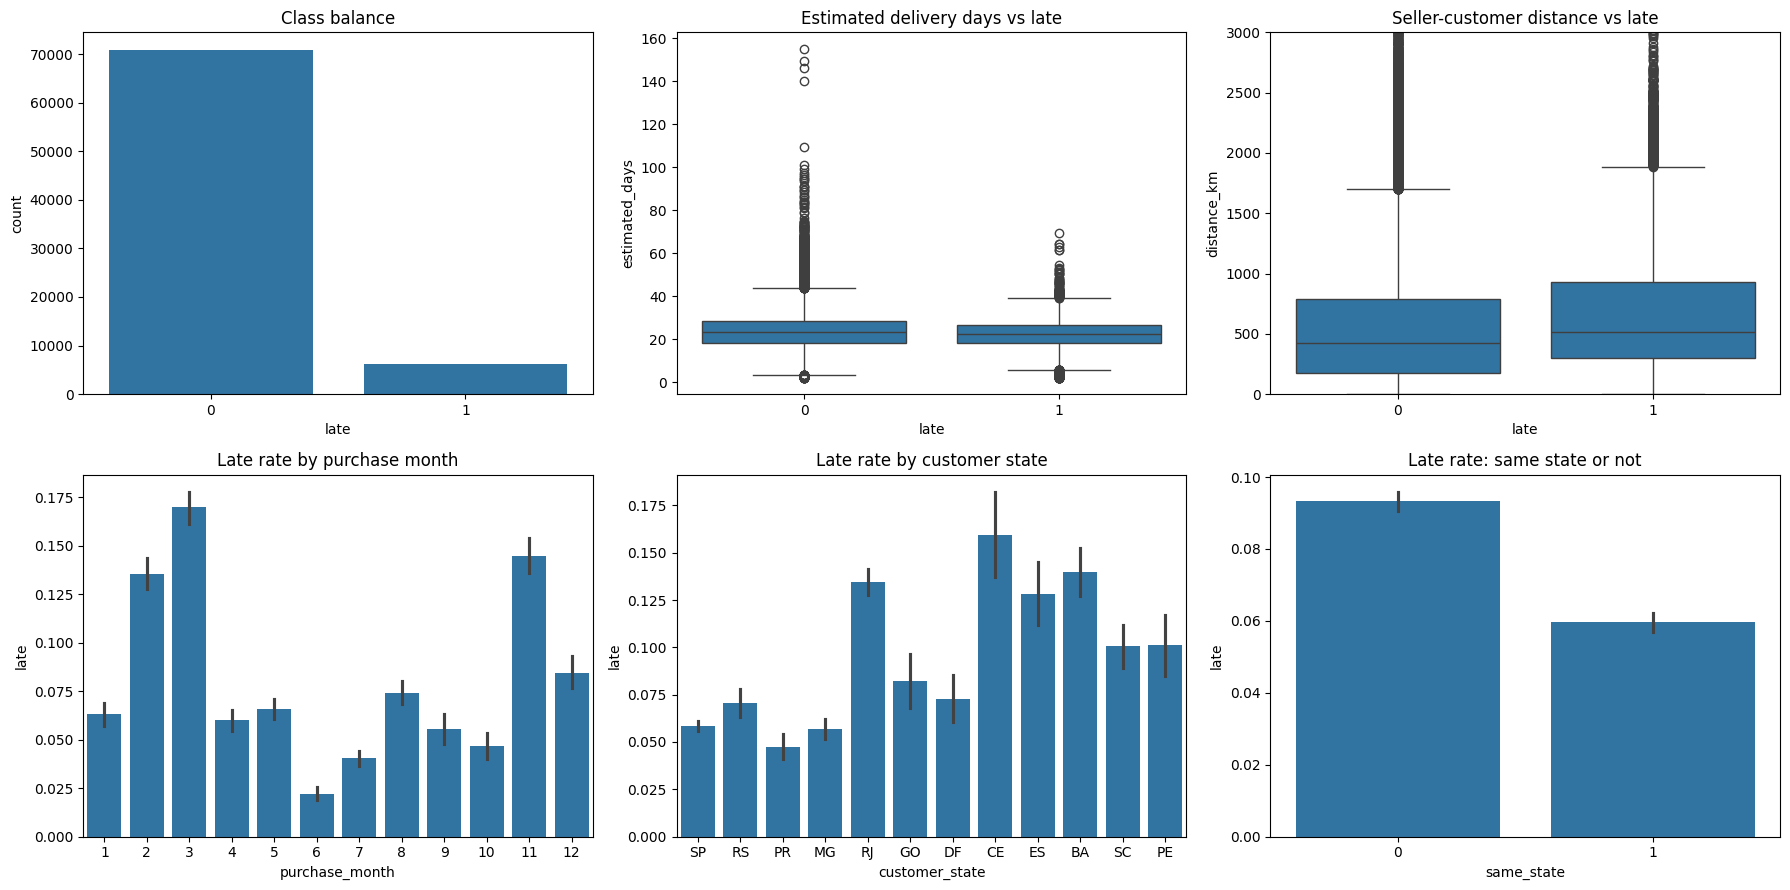

                                     mean  count
category                                        
food                             0.101124    356
construction_tools_construction  0.097436    585
office_furniture                 0.094153   1009
electronics                      0.093518   2021
baby                             0.093454   2215
furniture_living_room            0.089820    334
health_beauty                    0.089238   6802
furniture_decor                  0.089091   4950
                         mean  count
category                            
home_appliances      0.067912    589
cool_stuff           0.067352   2821
luggage_accessories  0.063063    777
pet_shop             0.062827   1337
small_appliances     0.057732    485
late                1.000000
distance_km         0.071601
freight             0.024293
product_weight_g    0.023796
volume_cm3          0.019084
price               0.016524
purchase_hour       0.009702
freight_ratio       0.006810
purchase_dow       

In [6]:
train = X_train.copy()
train["late"] = y_train

fig, ax = plt.subplots(2, 3, figsize=(18, 9))

sns.countplot(x="late", data=train, ax=ax[0, 0])
ax[0, 0].set_title("Class balance")

sns.boxplot(x="late", y="estimated_days", data=train, ax=ax[0, 1])
ax[0, 1].set_title("Estimated delivery days vs late")

sns.boxplot(x="late", y="distance_km", data=train, ax=ax[0, 2])
ax[0, 2].set_ylim(0, 3000)
ax[0, 2].set_title("Seller-customer distance vs late")

sns.barplot(x="purchase_month", y="late", data=train, ax=ax[1, 0])
ax[1, 0].set_title("Late rate by purchase month")

top_states = train["customer_state"].value_counts().head(12).index
sns.barplot(x="customer_state", y="late",
            data=train[train.customer_state.isin(top_states)], ax=ax[1, 1])
ax[1, 1].set_title("Late rate by customer state")

sns.barplot(x="same_state", y="late", data=train, ax=ax[1, 2])
ax[1, 2].set_title("Late rate: same state or not")

plt.tight_layout()
plt.show()

cat_rate = (train.groupby("category")["late"].agg(["mean", "count"])
            .query("count > 300").sort_values("mean", ascending=False))
print(cat_rate.head(8))
print(cat_rate.tail(5))

num = train.select_dtypes(include="number")
print(num.corr()["late"].sort_values(ascending=False))

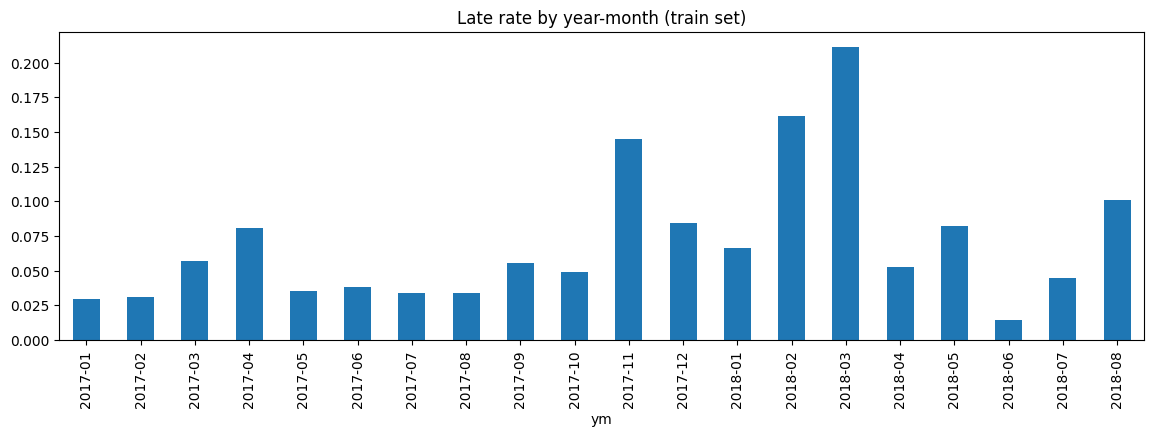

In [7]:
tmp = df.loc[X_train.index].copy()
tmp["ym"] = tmp["order_purchase_timestamp"].dt.to_period("M").astype(str)
ym = tmp.groupby("ym")["late"].agg(["mean", "count"])
ym = ym[ym["count"] > 300]
ym["mean"].plot(kind="bar", figsize=(14, 4), title="Late rate by year-month (train set)")
plt.show()

### EDA insights
1. **Imbalance:** only 8.1% of orders are late.
2. **Time:** the late rate changes a lot by period (about 2% in June vs 17% in March in the training set). The year-month chart shows these are spikes in specific periods (Nov 2017, Feb to Mar 2018), not a repeating yearly pattern.
3. **Geography:** customers in BA, RJ, CE and ES have late rates of 13 to 16%, versus 5 to 6% in SP, PR and MG.
4. **Distance:** orders shipped to a different state are late more often (about 9.3% vs 5.9%).
5. **Weak linear signals:** every numeric feature has a correlation under 0.08 with the target, so non-linear models are expected to do better than linear ones.

## 6. Preprocessing pipeline
Imputation, scaling and one-hot encoding live inside a scikit-learn `Pipeline` / `ColumnTransformer`, so they are fitted on training folds only (no leakage). Rare categories are grouped with `min_frequency`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()
print("cat:", cat_cols)
print("num:", num_cols)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False)),
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

cat: ['category', 'customer_state', 'seller_state']
num: ['purchase_month', 'purchase_dow', 'purchase_hour', 'estimated_days', 'n_items', 'price', 'freight', 'n_sellers', 'product_weight_g', 'volume_cm3', 'distance_km', 'same_state', 'freight_ratio']


## 7. Modeling
A majority-class baseline plus three models (Logistic Regression, Random Forest, Hist Gradient Boosting), compared with 5-fold stratified CV on the **training set only**. Hist Gradient Boosting is best (PR-AUC 0.292 vs 0.081 for the baseline). The baseline has recall 0, which shows why accuracy cannot be used here.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["average_precision", "roc_auc", "recall", "precision", "f1"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{m: round(res[f"test_{m}"].mean(), 3) for m in scoring}})

results = pd.DataFrame(rows).set_index("model")
results

,average_precision,roc_auc,recall,precision,f1
model,,,,,
Baseline (majority),0.081,0.500,0.000,0.000,0.000
Logistic Regression,0.183,0.708,0.643,0.143,0.234
Random Forest,0.275,0.777,0.525,0.234,0.324
Hist Gradient Boosting,0.292,0.788,0.037,0.596,0.069


## 8. Month check and tuning
Removing `purchase_month` lowers CV PR-AUC from 0.292 to 0.206, so it carries a lot of signal. But the year-month chart shows the late spikes happened in specific periods, so this feature may not generalize to the future (checked in section 10).

Random search (3-fold) gave CV PR-AUC 0.285, so tuning did not improve the score noticeably. I keep the tuned model because it is more regularized (`max_depth=6`, `l2_regularization=5`).

In [10]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.metrics import precision_recall_curve

def make_prep(drop=()):
    nc = [c for c in num_cols if c not in drop]
    return ColumnTransformer([("num", num_pipe, nc), ("cat", cat_pipe, cat_cols)])

for label, drop in [("with month", ()), ("without month", ("purchase_month",))]:
    pipe = Pipeline([("prep", make_prep(drop)),
                     ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                              random_state=RANDOM_STATE))])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["average_precision", "roc_auc"], n_jobs=-1)
    print(label, "PR-AUC:", res["test_average_precision"].mean().round(3),
          "ROC-AUC:", res["test_roc_auc"].mean().round(3))

with month PR-AUC: 0.292 ROC-AUC: 0.788
without month PR-AUC: 0.206 ROC-AUC: 0.725


In [11]:
pipe = Pipeline([("prep", preprocess),
                 ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])

param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [200, 300, 500],
    "model__max_depth": [None, 4, 6, 8],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 1, 5],
}

search = RandomizedSearchCV(pipe, param_dist, n_iter=15, scoring="average_precision",
                            cv=3, n_jobs=-1, random_state=RANDOM_STATE, verbose=1)
search.fit(X_train, y_train)
print(search.best_params_)
print("best CV PR-AUC:", round(search.best_score_, 3))
best = search.best_estimator_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__max_iter': 300, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__l2_regularization': 5}
best CV PR-AUC: 0.285


## 9. Choosing the decision threshold
Threshold chosen on out-of-fold predictions of the **training set**: 0.107 gives about 60% recall and 23% precision. This is a business assumption (a higher recall costs more false alarms), not a statistical optimum.

In [12]:
# 3) threshold choice using out-of-fold predictions on the TRAIN set
proba = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, proba)

for target in [0.5, 0.6, 0.7]:
    i = np.where(rec[:-1] >= target)[0][-1]
    print(f"recall >= {target}: threshold={thr[i]:.3f}  precision={prec[i]:.3f}  recall={rec[i]:.3f}")

recall >= 0.5: threshold=0.143  precision=0.270  recall=0.500
recall >= 0.6: threshold=0.107  precision=0.228  recall=0.600
recall >= 0.7: threshold=0.079  precision=0.190  recall=0.700


## 10. Time-based check
Train on the oldest 80% of orders, test on the newest 20%. The late rate in the newest 20% is 5.3% (vs 8.1% overall), so I compare **lift over the base rate**: with month PR-AUC is 0.102 (about 1.9x chance), without month 0.078 (about 1.5x). On future data the model is clearly weaker than on the random split (about 3.6x chance).

Note: the hyperparameters were selected on the random training set, which overlaps in time with this check, so it is an approximate check rather than a fully clean one.

In [13]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

order = df["order_purchase_timestamp"].sort_values().index
cut = int(len(order) * 0.8)
tr_idx, te_idx = order[:cut], order[cut:]
Xt, yt = X.loc[tr_idx], y.loc[tr_idx]
Xv, yv = X.loc[te_idx], y.loc[te_idx]
print("time-test base rate:", round(yv.mean(), 3))

best_model = best.named_steps["model"]
for label, drop in [("with month", ()), ("without month", ("purchase_month",))]:
    m = Pipeline([("prep", make_prep(drop)), ("model", clone(best_model))]).fit(Xt, yt)
    p = m.predict_proba(Xv)[:, 1]
    ap = average_precision_score(yv, p)
    print(label, "PR-AUC:", round(ap, 3), "| ROC-AUC:", round(roc_auc_score(yv, p), 3),
          "| lift over base rate:", round(ap / yv.mean(), 2))

time-test base rate: 0.053
with month PR-AUC: 0.102 | ROC-AUC: 0.717 | lift over base rate: 1.93
without month PR-AUC: 0.078 | ROC-AUC: 0.613 | lift over base rate: 1.48


## 11. Final evaluation on the untouched test set
On 19,294 test orders: PR-AUC 0.293, ROC-AUC 0.787. At the chosen threshold the model catches 61% of late orders (recall 0.606) with 23% precision: 948 of 1,565 late orders caught and 3,217 false alarms. CV and test scores are close, so there is no sign of overfitting. Accuracy (0.80) is lower than the "always on time" baseline (about 0.92), which is why it is not used.

Test PR-AUC : 0.293
Test ROC-AUC: 0.787
              precision    recall  f1-score   support

           0      0.959     0.819     0.883     17729
           1      0.228     0.606     0.331      1565

    accuracy                          0.801     19294
   macro avg      0.593     0.712     0.607     19294
weighted avg      0.900     0.801     0.839     19294



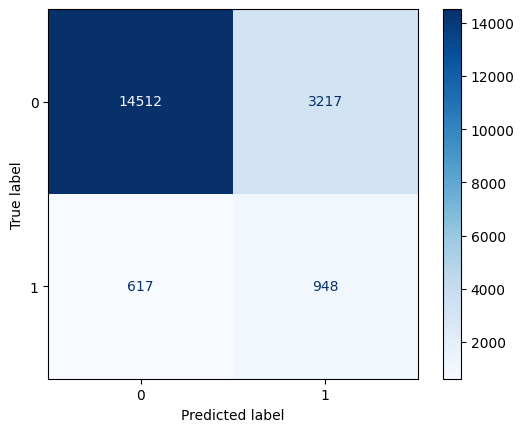

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

THRESHOLD = 0.107
p_test = best.predict_proba(X_test)[:, 1]
pred = (p_test >= THRESHOLD).astype(int)

print("Test PR-AUC :", round(average_precision_score(y_test, p_test), 3))
print("Test ROC-AUC:", round(roc_auc_score(y_test, p_test), 3))
print(classification_report(y_test, pred, digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap="Blues")
plt.show()

## 12. Error analysis
- The model flags far more orders in busy periods (59% of March orders) and almost none in calm months (1% in June, recall 0.05).
- Recall is higher for far and cross-state orders (about 0.78 above 1,000 km vs about 0.45 below 300 km).
- Missed late orders tend to be closer and cheaper to ship. A likely reason is seller or carrier problems that are not visible at purchase time (a hypothesis, not tested).
- `purchase_month` and `estimated_days` are the most important features, followed by customer state and distance.

In [15]:
res = X_test.copy()
res["y"] = y_test.values
res["p"] = p_test
res["pred"] = pred
res["dist_bucket"] = pd.cut(res["distance_km"], [0, 100, 300, 600, 1000, 2000, 10000])

def group_report(col, min_n=300):
    rows = []
    for k, d in res.groupby(col, observed=True):
        if len(d) < min_n:
            continue
        rows.append({
            col: k, "n": len(d),
            "late_rate": d["y"].mean(),
            "flag_rate": d["pred"].mean(),
            "recall": d.loc[d.y == 1, "pred"].mean() if d.y.sum() > 0 else np.nan,
            "precision": d.loc[d.pred == 1, "y"].mean() if d.pred.sum() > 0 else np.nan,
        })
    return pd.DataFrame(rows).set_index(col).round(3).sort_values("late_rate", ascending=False)

for c in ["customer_state", "purchase_month", "dist_bucket", "same_state"]:
    print(group_report(c), "\n")

# missed late orders vs caught late orders
print(res[res.y == 1].groupby("pred")[["estimated_days", "distance_km", "price", "freight", "volume_cm3"]]
      .mean().round(1))

                   n  late_rate  flag_rate  recall  precision
customer_state                                               
BA               641      0.142      0.437   0.780      0.254
RJ              2494      0.136      0.362   0.764      0.287
PE               310      0.135      0.361   0.476      0.179
ES               410      0.100      0.361   0.707      0.196
SC               725      0.086      0.292   0.613      0.179
GO               401      0.080      0.274   0.594      0.173
RS              1070      0.076      0.231   0.617      0.202
DF               445      0.063      0.249   0.643      0.162
SP              8062      0.061      0.125   0.424      0.207
PR               967      0.060      0.104   0.397      0.228
MG              2219      0.053      0.137   0.517      0.200 

                   n  late_rate  flag_rate  recall  precision
purchase_month                                               
3               1925      0.178      0.587   0.872      0.265
11    

purchase_month      0.1422
estimated_days      0.1117
customer_state      0.0632
distance_km         0.0345
same_state          0.0139
seller_state        0.0097
freight             0.0059
n_items             0.0031
freight_ratio       0.0018
purchase_dow        0.0015
product_weight_g    0.0013
n_sellers           0.0010
category            0.0003
price              -0.0018
purchase_hour      -0.0021
volume_cm3         -0.0051
dtype: float64


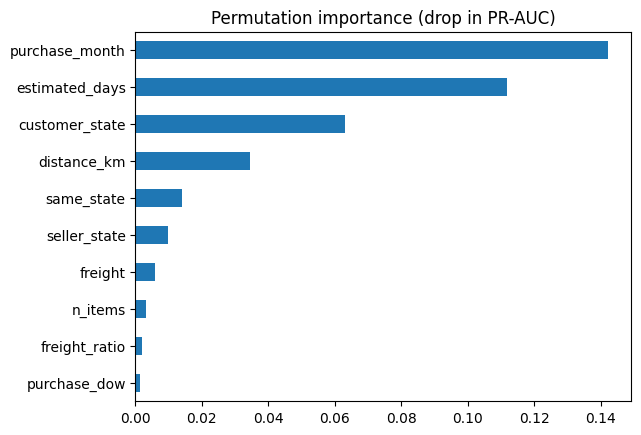

In [16]:
from sklearn.inspection import permutation_importance

samp = X_test.sample(6000, random_state=RANDOM_STATE)
r = permutation_importance(best, samp, y_test.loc[samp.index],
                           scoring="average_precision", n_repeats=3,
                           random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.round(4))
imp.head(10).sort_values().plot(kind="barh", title="Permutation importance (drop in PR-AUC)")
plt.show()

## 13. How the business can use the score
Ranking orders by risk and reviewing only the top share:

In [17]:
order_idx = np.argsort(-p_test)
for frac in [0.05, 0.10, 0.20]:
    k = int(len(p_test) * frac)
    hits = y_test.values[order_idx[:k]].sum()
    print(f"top {frac:.0%}: precision={hits/k:.3f} recall={hits/y_test.sum():.3f} lift={hits/k/y_test.mean():.2f}")

top 5%: precision=0.401 recall=0.247 lift=4.95
top 10%: precision=0.322 recall=0.397 lift=3.97
top 20%: precision=0.241 recall=0.594 lift=2.97


## 14. Business recommendation
- Use the score to **rank orders by risk**, not as a final yes or no.
- If the team can review only 10% of orders, those orders contain about 40% of all late deliveries, with a late rate of 32% vs 8% on average. Reviewing 20% catches about 59%.
- Warn customers early and escalate with carriers for far, cross-state orders (for example BA and RJ), and in periods the model flags as high risk.
- Investigate what caused the Nov 2017 and Feb to Mar 2018 spikes before treating them as seasonal.
- Watch sellers with high late rates (seller page in the app).

## Limitations
- One marketplace, 2016 to 2018.
- On a time-based split the model is weaker: PR-AUC 0.102, about 1.9x better than chance (vs about 3.6x on the random split).
- The model does not see seller or carrier problems that happen after purchase.
- Distance in the app is approximated from state centers.
- The risk-level cut-offs used in the app (top 5% / 10% / 20%) are computed from the test-set score distribution; in production they should be computed on a separate validation set.

## 15. Save files for the Streamlit app
The tuned pipeline, a few lookup tables and a small config file are saved to `artifacts/`. They are uploaded to the GitHub repo and loaded by `app.py`.

In [18]:
import joblib, json, os
os.makedirs("artifacts", exist_ok=True)

joblib.dump(best, "artifacts/late_delivery_pipeline.joblib")

df.groupby("customer_state")[["cust_lat", "cust_lng"]].mean().to_csv("artifacts/customer_state_centroids.csv")
df.groupby("seller_state")[["sell_lat", "sell_lng"]].mean().to_csv("artifacts/seller_state_centroids.csv")

sellers_stats = (df.groupby(["seller_id", "seller_state"])
                   .agg(n_orders=("late", "size"), late_rate=("late", "mean"))
                   .reset_index())
sellers_stats = sellers_stats[sellers_stats["n_orders"] >= 30].round(4)
sellers_stats.to_csv("artifacts/seller_stats.csv", index=False)

config = {
    "threshold": 0.107,
    "categories": sorted(X["category"].dropna().unique().tolist()),
    "customer_states": sorted(X["customer_state"].dropna().unique().tolist()),
    "seller_states": sorted(X["seller_state"].dropna().unique().tolist()),
    "median_weight_g": float(X_train["product_weight_g"].median()),
    "median_volume_cm3": float(X_train["volume_cm3"].median()),
}
json.dump(config, open("artifacts/config.json", "w"), indent=2)

print(os.listdir("artifacts"), len(sellers_stats))

['seller_state_centroids.csv', 'seller_stats.csv', 'late_delivery_pipeline.joblib', 'config.json', 'customer_state_centroids.csv'] 621


In [19]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

cfg = json.load(open("artifacts/config.json"))
cfg["q95"] = float(np.quantile(p_test, 0.95))
cfg["q90"] = float(np.quantile(p_test, 0.90))
cfg["q80"] = float(np.quantile(p_test, 0.80))
cfg["same_state_median_km"] = float(df.loc[df.same_state == 1, "distance_km"].median())
json.dump(cfg, open("artifacts/config.json", "w"), indent=2)
print({k: round(v, 3) for k, v in cfg.items() if isinstance(v, float)})

!zip -r artifacts.zip artifacts
from google.colab import files
files.download("artifacts.zip")

scikit-learn version: 1.6.1
{'threshold': 0.107, 'median_weight_g': 700.0, 'median_volume_cm3': 6375.0, 'q95': 0.278, 'q90': 0.191, 'q80': 0.114, 'same_state_median_km': 96.151}
  adding: artifacts/ (stored 0%)
  adding: artifacts/seller_state_centroids.csv (deflated 43%)
  adding: artifacts/seller_stats.csv (deflated 46%)
  adding: artifacts/late_delivery_pipeline.joblib (deflated 64%)
  adding: artifacts/config.json (deflated 65%)
  adding: artifacts/customer_state_centroids.csv (deflated 43%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>